In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy


today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data, keepdims=True))
    return fig

**Load Data**

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
regions_f = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed'
DHS_mapped_path = datadir + 'regions_25kb_CT20230118.DHSsignalmapped.bed'
DHS_factor_z_f = datadir + 'regions_25kb_CT20230202.DHSsignalzscores.hdf5'
DHS_factorblind_z_f = datadir + 'regions_25kb_CT20230202.DHSsignal.factorblindzscores.hdf5'
DHS_enrich_f = datadir + 'regions_25kb_CT20230202.DHS.counts.enrichment.hdf5'

In [4]:
f = open(regions_f, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

In [5]:
f = open(DHS_mapped_path, 'r')
DHS_factor_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

DHS_hdf5 = h5py.File(DHS_factor_z_f, 'r')
DHS_neural_z = DHS_hdf5['z'][:, np.where(DHS_factor_order=='Neural')[0][0]]
DHS_neural_mean = DHS_hdf5['means'][:, np.where(DHS_factor_order=='Neural')[0][0]]
DHS_neural_mean = np.where(np.isnan(DHS_neural_mean), 0, DHS_neural_mean)
DHS_neural_counts = DHS_hdf5['counts'][:, np.where(DHS_factor_order=='Neural')[0][0]]
DHS_hdf5.close()

DHS_hdf5 = h5py.File(DHS_factorblind_z_f, 'r')
DHS_fb_z = DHS_hdf5['factor_blind_z'][:]
regional_DHS_counts = DHS_hdf5['counts'][:]
regional_DHS_means = DHS_hdf5['means'][:]
DHS_hdf5.close()

DHS_hdf5 = h5py.File(DHS_enrich_f, 'r')
DHS_neural_enrich = DHS_hdf5['enrichment'][:, np.where(DHS_factor_order=='Neural')[0][0]]
DHS_nerual_counts = DHS_hdf5['counts'][:, np.where(DHS_factor_order=='Neural')[0][0]]
DHS_hdf5.close()

In [6]:
metadata = np.hstack((DHS_neural_counts.reshape(-1, 1),
                      DHS_neural_mean.reshape(-1, 1),
                      regional_DHS_counts.reshape(-1, 1),
                      regional_DHS_means.reshape(-1, 1)))

In [7]:
m = np.char.add(metadata[:, 0].astype(int).astype(str), 
                np.array(['/']*len(metadata)))
m = np.char.add(m, 
                np.round(metadata[:, 1], 3).astype(str))
m = np.char.add(m, 
                np.array(['/']*len(metadata)))
m = np.char.add(m, 
                metadata[:, 2].astype(int).astype(str))
m = np.char.add(m, 
                np.array(['/']*len(metadata)))
m = np.char.add(m, 
                np.round(metadata[:, 3], 3).astype(str))

m = m.reshape(-1, 1)

In [9]:
# # file for WM
# r_z_enrich = np.hstack((regions,
#                         DHS_neural_enrich.reshape(-1, 1),
#                         DHS_neural_z.reshape(-1, 1)))
# outfile = datadir + 'regions_25kb_CT20230202.DHS.neural.factor_enrichment.Z.bed'
# np.savetxt(outfile, 
#            r_z_enrich, 
#            delimiter='\t', 
#            fmt='%s')

In [8]:
DHSalpha2paper_order = np.array([8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14])
DHSder2paper_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])

f = open(DHS_mapped_path, 'r')
DHS_factor_order = np.array(f.readline().strip().split('\t'))[3:][DHSalpha2paper_order]
f.close()

In [9]:
import gzip
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', 'r')
mixture = np.load(fn)[DHSder2paper_order, :]

In [10]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=0)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (3) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [47]:
DHS_regions = DHS_metadata[['seqname', 'start', 'end']].to_numpy()

**Functions**

In [72]:
def region_percentile(arr):
    # rank each region
    ranked_regions = rankdata(arr)

    # find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr)

    # adjusting/resetting ranks
    ranked_regions = ranked_regions - comp_num_zero
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)
    
    percentile = ranked_regions / np.max(ranked_regions)

    return percentile

In [73]:
def print_coords(i):
    c = regions[i]
    return c[0] + ':' + c[1] + '-' + c[2]

In [74]:
def roiurl(top_regions, method):
    today = date.today()
    roiurl_name = 'top_neural_regions_' + method + '_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path_index = 'https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    print(link_path_index)
    return 

**Percentiles**

In [31]:
neural_z_per = region_percentile(DHS_neural_z)
fb_z_per = region_percentile(DHS_fb_z)
neural_enrich_per = region_percentile(DHS_neural_enrich)
neural_counts_per = region_percentile(DHS_neural_counts)

**Top regions**

Z score

In [181]:
inds = np.argsort(-neural_z_per)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'factor_z_score')
# not bad

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_factor_z_score_25kb_CT20230202.bed


Enrichment

In [182]:
inds = np.argsort(-neural_enrich_per)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'factor_enrichment')
# not good, single DHSs

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_factor_enrichment_25kb_CT20230202.bed


Enrichment + Z score

In [183]:
inds = np.argsort(-(neural_z_per + neural_enrich_per) / 2)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'factor_z_score_and_enrichment')
# this seems to be best

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_factor_z_score_and_enrichment_25kb_CT20230202.bed


Factor Blind Z Score + Enrichment

In [184]:
inds = np.argsort(-(fb_z_per + neural_enrich_per) / 2)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'factor_blind_z_score_and_enrichment')
# some great regions, some bad ones driven by other factors

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_factor_blind_z_score_and_enrichment_25kb_CT20230202.bed


Factor Blind + Dependent Z Scores

In [185]:
inds = np.argsort(-(fb_z_per + neural_z_per) / 2)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'factor_blind_and_dependent_z_scores')
# neural sections within each of these regions, but not any whole region dominated by neural

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_factor_blind_and_dependent_z_scores_25kb_CT20230202.bed


Neural DHS count + Neural Enrichment

In [32]:
inds = np.argsort(-(neural_counts_per + neural_enrich_per) / 2)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'neural_counts_and_enrichment')

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_neural_counts_and_enrichment_25kb_CT20230203.bed


**KL divergence on mixture**

Text(0.5, 1.0, 'Comparing Number of Samples and NMF Loading Sums for DHSs')

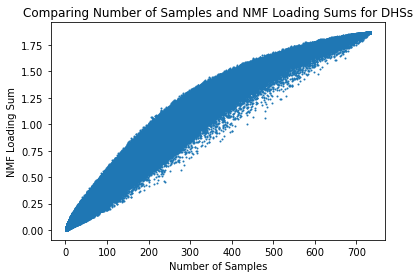

In [7]:
fig = plt.figure()
fig.patch.set_facecolor('white')
    
plt.scatter(DHS_metadata['numsamples'].to_numpy(), np.sum(mixture, axis=0), s=1)
plt.xlabel('Number of Samples')
plt.ylabel('NMF Loading Sum')


plt.title('Comparing Number of Samples and NMF Loading Sums for DHSs')

In [8]:
# building a 17th leftover component
loading_sums = np.sum(mixture, axis=0)
max_loading_sum = np.max(loading_sums)
leftover_comp = max_loading_sum - loading_sums
mixture = np.vstack((mixture, leftover_comp))

In [47]:
# normalize mixture loadings
mixture_norm = mixture / np.sum(mixture, axis=0)
# find expected
exp = np.mean(mixture_norm, axis=1)

In [11]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
for factor, ind in zip(DHS_factor_order, range(len(DHS_factor_order))):
    out = np.hstack((DHS_regions, 
                     np.array([factor] * len(DHS_regions)).reshape(-1, 1),
                     mixture_norm[ind, :].reshape(-1, 1)))
    outfile = datadir + 'DHS_NMF_loading_leftovernorm_component_bed_CT20230209/' + factor +'.bed'
    np.savetxt(outfile, 
               out, 
               delimiter='\t', 
               fmt='%s')

In [10]:
# use KL for DHS loadings
mixture_scores = mixture_norm * np.log2((mixture_norm.T / exp).T)
mixture_scores = np.where(np.isnan(mixture_scores), 0, mixture_scores) 

/tmp/ipykernel_5624/2263202840.py:2: RuntimeWarning: divide by zero encountered in log2
  mixture_scores = mixture_norm * np.log2((mixture_norm.T / exp).T)
/tmp/ipykernel_5624/2263202840.py:2: RuntimeWarning: invalid value encountered in multiply
  mixture_scores = mixture_norm * np.log2((mixture_norm.T / exp).T)


In [12]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
for factor, ind in zip(DHS_factor_order, range(len(DHS_factor_order))):
    out = np.hstack((DHS_regions, 
                     np.array([factor] * len(DHS_regions)).reshape(-1, 1),
                     mixture_scores[ind, :].reshape(-1, 1)))
    outfile = datadir + 'DHS_KL_component_bed_CT20230208/' + factor +'.bed'
    np.savetxt(outfile, 
               out, 
               delimiter='\t', 
               fmt='%s')

In [ ]:
"""
bed files mapped to ref file in the same way as epilogos bed files
"""

Results

Mean mapped

In [196]:
DHS_KLmean_f = datadir + 'regions_25kb_CT20230209.DHS.KL.statemeans.hdf5'
DHS_hdf5 = h5py.File(DHS_KLmean_f, 'r')
factor_order = np.char.decode(DHS_hdf5['factors'][:])
print(np.where(factor_order=='Neural')[0])
print(factor_order)
DHS_neural_KLmean = DHS_hdf5['state_means'][:, np.where(factor_order=='Neural')[0][0]]
DHS_hdf5.close()

DHS_neural_KLmean = np.where(DHS_neural_KLmean < 0, 0, DHS_neural_KLmean)

[6]
['Cancer_epithelial' 'Cardiac' 'Digestive' 'Lymphoid' 'Musculoskeletal'
 'Myeloid_erythroid' 'Neural' 'Organdevel_renal' 'Placental_trophoblast'
 'Primitive_embryonic' 'Pulmonarydevel' 'Renal_cancer' 'StromalA'
 'StromalB' 'Tissueinvariant' 'Vascular_endothelial']


In [197]:
neural_KLmean_per = region_percentile(DHS_neural_KLmean)
regional_counts_per = region_percentile(regional_DHS_counts)

In [198]:
inds = np.argsort(-neural_KLmean_per)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'DHS_KL_means')
print(inds[0])

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_DHS_KL_means_25kb_CT20230209.bed
72580


In [106]:
DHS_metadata[DHS_metadata['identifier']==7.51307]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
3036029,chr7,73154874,73155035,7.51307,1.15756,606,73154910,73154875.0,73154970.0,Tissue invariant


In [163]:
print(mixture_norm[7, 3036029])
print(mixture_scores[7, 3036029])

0.05001737664680163
0.19524037537578837


In [164]:
np.where(np.argsort(-mixture_norm[7])==3036029)[0]

array([36287])

In [165]:
np.max(mixture_norm[7]), np.argmax(mixture_norm[7])

(0.09215966793949981, 1909927)

In [167]:
DHS_factor_order

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant'], dtype='<U21')

In [168]:
mixture_norm[:, np.argmax(mixture_norm[7])][[13, 7]] # pulmonary, neural

array([0.09350592, 0.09215967])

In [169]:
np.argmax(mixture_norm[7])

1909927

In [116]:
DHS_metadata.loc[[1909927]]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1909927,chr20,20498420,20498880,20.386353,2.368668,147,20498590,20498472.0,20498790.0,Pulmonary devel.


In [170]:
i = np.argsort(-mixture_norm[7])[0]
chrm = DHS_metadata.loc[i]['seqname']
start = DHS_metadata.loc[i]['start']
end = DHS_metadata.loc[i]['end']
    

In [171]:
np.where(
    ((regions[:, 0]==chrm) & 
    (regions[:, 1].astype(int) <= start) & 
    (regions[:, 2].astype(int) >= end))
)

(array([44413]),)

In [172]:
DHS_neural_KLmean[44413]

0.016085

In [177]:
np.argmax(neural_KLmean_per)

72580

In [139]:
DHS_neural_KLmean[np.argmax(neural_KLmean_per)]

0.19524

In [140]:
np.max(DHS_neural_KLmean)

0.19524

In [184]:
print(print_coords(44413))

chr20:20493556-20518556


In [192]:
DHSs_in_region = np.where(
    ((DHS_metadata['seqname']==regions[44413, 0]) &
     (DHS_metadata['start']>=regions[44413, 1].astype(int)) &
     (DHS_metadata['end']<=regions[44413, 2].astype(int)))
)[0]
DHSs_in_region = np.append(DHSs_in_region, [1909947, 1909948])

In [199]:
np.round(mixture_scores[7, DHSs_in_region], 5)

array([-1.510e-03, -1.500e-03,  0.000e+00,  0.000e+00,  0.000e+00,
        2.300e-04,  1.390e-03,  0.000e+00,  0.000e+00,  0.000e+00,
        0.000e+00,  4.410e-01, -1.510e-03, -1.480e-03,  7.795e-02,
        0.000e+00,  7.700e-03,  0.000e+00,  0.000e+00,  0.000e+00,
        0.000e+00, -1.770e-03,  1.003e-02,  0.000e+00,  0.000e+00,
       -1.730e-03,  0.000e+00, -1.420e-03,  5.410e-03, -1.630e-03,
       -3.600e-04,  0.000e+00,  0.000e+00])

In [194]:
print(np.mean(mixture_scores[:, DHSs_in_region], axis=1)[7])
print(DHS_neural_KLmean[44413])


0.01608467349265313
0.016085


In [203]:
inds = np.argsort(-(neural_KLmean_per + regional_counts_per) / 2)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'regional_counts_and_DHS_KL_means')

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_regional_counts_and_DHS_KL_means_25kb_CT20230209.bed


Sum mapped

In [208]:
DHS_KLenrich_f = datadir + 'regions_25kb_CT20230209.DHS.KL.statesums.hdf5'
DHS_hdf5 = h5py.File(DHS_KLenrich_f, 'r')
factor_order = np.char.decode(DHS_hdf5['factors'][:])
print(np.where(factor_order=='Neural')[0])
print(factor_order)
DHS_neural_KLsum = DHS_hdf5['state_sums'][:, np.where(factor_order=='Neural')[0][0]]
DHS_cardiac_KLsum = DHS_hdf5['state_sums'][:, np.where(factor_order=='Cardiac')[0][0]]
DHS_hdf5.close()

DHS_neural_KLsum = np.where(DHS_neural_KLsum < 0, 0, DHS_neural_KLsum)
DHS_cardiac_KLsum = np.where(DHS_cardiac_KLsum < 0, 0, DHS_cardiac_KLsum)

[6]
['Cancer_epithelial' 'Cardiac' 'Digestive' 'Lymphoid' 'Musculoskeletal'
 'Myeloid_erythroid' 'Neural' 'Organdevel_renal' 'Placental_trophoblast'
 'Primitive_embryonic' 'Pulmonarydevel' 'Renal_cancer' 'StromalA'
 'StromalB' 'Tissueinvariant' 'Vascular_endothelial']


In [209]:
neural_KLsum_per = region_percentile(DHS_neural_KLsum)
cardiac_KLsum_per = region_percentile(DHS_cardiac_KLsum)

In [207]:
inds = np.argsort(-neural_KLsum_per)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'DHS_KL_sum')

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_DHS_KL_sum_25kb_CT20230209.bed


In [220]:
DHS_metadata[DHS_metadata['identifier']==11.536368]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
565870,chr11,65489480,65490382,11.536368,0.472635,3,65489610,65489610.0,65489629.0,Lymphoid


In [222]:
mixture_norm[:, 565902]

array([0.03858163, 0.07550326, 0.0470425 , 0.03642577, 0.02496182,
       0.03942611, 0.07524778, 0.04964157, 0.03928713, 0.10200057,
       0.0207308 , 0.05032602, 0.03800322, 0.03189936, 0.02777445,
       0.28017866, 0.02296935])

In [224]:
inds = np.argsort(-cardiac_KLsum_per)[:100]
roiurl((regions[inds]), 'DHS_KL_sum')

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_cardiac_regions_DHS_KL_sum_25kb_CT20230209.bed


KL method 2

In [190]:
filename = datadir + 'regions_25kb_CT20230209.DHS.NMFnormloadingmapped.bed'
f = open(filename, 'r')
DHS_factors = np.array(f.readline().strip().split('\t')[3:])
means = []
for line in f.readlines():
    line = line.strip().split('\t')[3:]
    if line:
        factor_means = []
        for factor_loadings in line:
            factor_mean = np.mean(np.float_(factor_loadings.split(';')))
            factor_means.append(factor_mean)
        factor_means = np.array(factor_means)
    else:
        factor_means = np.zeros(16)
    means.append(factor_means)
f.close()

means = np.array(means)

In [191]:
mixture_scores_2 = means * np.log2(means / exp[:-1])
mixture_scores_2 = np.where(np.isnan(mixture_scores_2), 0, mixture_scores_2)

/tmp/ipykernel_42041/2189578099.py:1: RuntimeWarning: divide by zero encountered in log2
  mixture_scores_2 = means * np.log2(means / exp[:-1])
/tmp/ipykernel_42041/2189578099.py:1: RuntimeWarning: invalid value encountered in multiply
  mixture_scores_2 = means * np.log2(means / exp[:-1])


In [192]:
DHS_neural_KLmean_2 = mixture_scores_2[:, np.where(DHS_factors=='Neural')[0][0]]

In [193]:
neural_KLmean_2_per = region_percentile(DHS_neural_KLmean_2)

In [199]:
inds_2 = np.argsort(-neural_KLmean_2_per)[:100]
roiurl(np.hstack((regions[inds_2], m[inds_2])), 'DHS_KL_2_means')

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_DHS_KL_2_means_25kb_CT20230209.bed


In [203]:
inds_set = set(inds) #method 1
inds_2_set = set(inds_2) #method2

In [210]:
print(len(inds_set - inds_2_set))

18


**Count and Enrichment with Mixture**

In [17]:
for factor, f_sum, f_max, f_min in zip(DHS_factor_order, np.sum(mixture, axis=1), np.max(mixture, axis=1), np.min(mixture, axis=1)):
    print(factor, 
          '\t',
          np.round(f_sum, 4), 
          '\t',
          np.round(f_max, 4), 
          '\t',
          np.round(f_min, 4))

Placental_trophoblast 	 19480.6748 	 0.116 	 0.0
Lymphoid 	 17063.1587 	 0.1878 	 0.0
Myeloid_erythroid 	 17208.9817 	 0.1523 	 0.0
Cardiac 	 15871.3286 	 0.1528 	 0.0
Musculoskeletal 	 17548.6821 	 0.2414 	 0.0
Vascular_endothelial 	 14406.2492 	 0.1364 	 0.0
Primitive_embryonic 	 33901.6368 	 0.254 	 0.0
Neural 	 22437.7545 	 0.1722 	 0.0
Digestive 	 12730.9598 	 0.1864 	 0.0
StromalA 	 17155.8354 	 0.2896 	 0.0
StromalB 	 40856.0371 	 0.2572 	 0.0
Renal_cancer 	 23915.8323 	 0.189 	 0.0
Cancer_epithelial 	 17220.1533 	 0.1356 	 0.0
Pulmonarydevel 	 12781.1669 	 0.204 	 0.0
Organdevel_renal 	 18666.959 	 0.2517 	 0.0
Tissueinvariant 	 18014.2037 	 0.6037 	 0.0


In [33]:
mixture_max = np.max(mixture, axis=1).reshape(-1, 1)
mixture_min = np.min(mixture, axis=1).reshape(-1, 1)

In [37]:
mixture_fnorm = (mixture - mixture_min) / (mixture_max - mixture_min)

In [57]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
for factor, ind in zip(DHS_factor_order, range(len(DHS_factor_order))):
    out = np.hstack((DHS_regions, 
                     np.array([factor] * len(DHS_regions)).reshape(-1, 1),
                     mixture_fnorm[ind, :].reshape(-1, 1)))
    outfile = datadir + 'DHS_NMF_factor_norm_bed_CT20230210/' + factor +'.bed'
    np.savetxt(outfile, 
               out, 
               delimiter='\t', 
               fmt='%s')

In [64]:
np.where(factor_order=='Neural')[0][0]

7

In [83]:
DHS_NMFsum_f = datadir + 'regions_25kb_CT20230210.DHS.factornormNMF.factorsums.hdf5'

DHS_hdf5 = h5py.File(DHS_NMFsum_f, 'r')
factor_order = np.char.decode(DHS_hdf5['factors'][:])[DHSalpha2paper_order]
DHS_NMFsum = DHS_hdf5['factor_sums'][:][:, DHSalpha2paper_order]
DHS_hdf5.close()

DHS_NMFsum_neural = DHS_NMFsum[:, np.where(factor_order=='Neural')[0][0]]
DHS_NMFsum_total = np.sum(DHS_NMFsum, axis=1)

In [87]:
NMFsum_enrich_neural = DHS_NMFsum_neural / DHS_NMFsum_total
NMFsum_enrich_neural = np.where(np.isnan(NMFsum_enrich_neural), 0, NMFsum_enrich_neural)

/tmp/ipykernel_70954/282997777.py:1: RuntimeWarning: invalid value encountered in true_divide
  NMFsum_enrich_neural = DHS_NMFsum_neural / DHS_NMFsum_total


In [89]:
NMFsum_enrich_neural_per = region_percentile(NMFsum_enrich_neural)
NMFsum_neural_per = region_percentile(DHS_NMFsum_neural)

In [94]:
inds = np.argsort(-(NMFsum_neural_per + NMFsum_enrich_neural_per) / 2)[:100]
roiurl(np.hstack((regions[inds], m[inds])), 'neural_NMFsum_count_and_enrichment')

https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftop_neural_regions_neural_NMFsum_count_and_enrichment_25kb_CT20230210.bed
